# 11 · Readable claim patterns: association rules and their limits
**DSC 411/511 graduate project · Venkat Repaka and Ritik Gaire**

**Question:** which combinations of simple facts go with major damage, and do these rules still work in later years?

We turn each claim into a set of yes/no facts, mine rules with Apriori and FP-Growth, and test the frozen rules on later years. We also explain why building histories cannot be mined from this file.

## 1. Define one transaction and one outcome
A transaction is one claim with a usable damage ratio. Its items are recorded facts about the building, policy, approximate event exposure and neighborhood. Our outcome is damage above 25% of reported building value; it differs from notebook 03's dollar threshold.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from IPython.display import display,Markdown
from mlxtend.frequent_patterns import apriori,fpgrowth,association_rules
from project_utils import *
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
df=load_joined()
d=df[df.damage_ratio.notna()].copy()
train=d.loss_year.le(2023);test=d.loss_year.ge(2024)
TARGET='damage over 25% of value'
print(f'Transactions: {len(d):,}; earlier {train.sum():,}; later {test.sum():,}')

Transactions: 217,034; earlier 124,355; later 92,679


### 1.1 Turn records into facts with visible cut points
The age, coverage, rain and track boundaries are declared analysis choices. A missing value does not assert the fact. Therefore, absence of an item can mean the opposite fact or an unknown value; we do not mine rules about absence.

Census context and revised weather remain retrospective inputs. None of the antecedent facts uses payment or damage itself.

In [2]:
acs=pd.read_parquet(DATA/'acs_blockgroups.parquet')
low_income=acs.median_household_income.quantile(.2)
B=pd.DataFrame({
 'zone AE':d.zone.eq('AE'),'zone X':d.zone.eq('X'),
 'slab foundation':d.foundation.eq('1'),'elevated foundation':d.foundation.isin(['4','5','6']),
 'single family':d.occupancy.eq('11'),'condo building':d.occupancy.eq('15'),'mobile home':d.occupancy.eq('14'),
 'building older than 40':d.building_age.gt(40),'coverage at least $250k':d.totalBuildingInsuranceCoverage.ge(250000),
 'main residence':d.primaryResidenceIndicator.eq(1),'Florida':d.state.eq('FL'),'named event':d.floodEvent.notna(),
 'five-day rain at least 150mm':d.rain_5d_mm.ge(150),'hurricane within 100km':d.trk_dist_km.le(100),
 'lowest-income area group':d.median_household_income.le(low_income),
 TARGET:d.damage_ratio.gt(.25)},index=d.index).fillna(False).astype(bool)
display(B.mean().sort_values(ascending=False).to_frame('share of transactions').round(3))
display(B.head().astype(int))

,share of transactions
named event,0.810
single family,0.776
zone AE,0.727
main residence,0.672
building older than 40,0.665
coverage at least $250k,0.644
Florida,0.540
slab foundation,0.538
five-day rain at least 150mm,0.479
hurricane within 100km,0.412


,zone AE,zone X,slab foundation,elevated foundation,single family,condo building,mobile home,building older than 40,coverage at least $250k,main residence,Florida,named event,five-day rain at least 150mm,hurricane within 100km,lowest-income area group,damage over 25% of value
0,1,0,1,0,0,0,0,1,1,0,1,1,0,0,0,1
2,1,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0
3,1,0,1,0,1,0,0,1,0,1,1,1,0,0,0,1
4,1,0,1,0,1,0,0,0,0,0,0,1,1,0,0,1
5,1,0,1,0,1,0,0,1,1,1,1,1,0,0,0,1


**What we changed.** We replaced many measurements with readable binary facts. This loses detail. A house aged 41 and one aged 90 now share the same age item. The rules can only find patterns allowed by our chosen items.

## 2. Begin with frequent pairs before applying a mining algorithm
Support is the fraction of transactions containing every item in a set. We calculate a few supports directly so that the package output is understandable.

In [3]:
Bt=B.loc[train]
examples=[['slab foundation'],['zone AE','slab foundation'],['zone AE','slab foundation',TARGET]]
for items in examples:
    count=Bt[items].all(axis=1).sum()
    print(' AND '.join(items),f': {count:,} earlier claims; support {count/len(Bt):.3f}')

slab foundation : 58,519 earlier claims; support 0.471
zone AE AND slab foundation : 41,412 earlier claims; support 0.333
zone AE AND slab foundation AND damage over 25% of value : 21,981 earlier claims; support 0.177


### 2.1 Compare Apriori and FP-Growth on the same problem
Apriori grows candidate sets from common smaller sets. FP-Growth compresses shared patterns in a tree. We cap itemsets at three items, allowing a two-fact antecedent and one outcome. We benchmark here rather than assuming one algorithm must be faster.

In [4]:
MIN_SUPPORT=.02;MAX_LEN=3
start=time.perf_counter();fi_a=apriori(Bt,min_support=MIN_SUPPORT,use_colnames=True,max_len=MAX_LEN)
apriori_seconds=time.perf_counter()-start
start=time.perf_counter();fi=fpgrowth(Bt,min_support=MIN_SUPPORT,use_colnames=True,max_len=MAX_LEN)
fpgrowth_seconds=time.perf_counter()-start
set_a={frozenset(v) for v in fi_a.itemsets};set_f={frozenset(v) for v in fi.itemsets}
assert set_a==set_f
mining=pd.DataFrame({'method':['Apriori','FP-Growth'],'seconds':[apriori_seconds,fpgrowth_seconds],
                     'frequent itemsets':[len(fi_a),len(fi)]}).set_index('method')
display(mining.round(3));save_table(mining,'11_mining_comparison')

,seconds,frequent itemsets
method,,
Apriori,0.071,430
FP-Growth,0.539,430


**Decision.** Both algorithms must find the same supported sets with the same settings. Runtime is a practical choice, not evidence of a better rule. With only a few facts, either can be adequate. Support and maximum length control what can be discovered before a ranking measure is chosen.

## 3. Start with confidence, then challenge it
For A → B, confidence is P(B | A). A common outcome can create high confidence even when A adds little. Lift divides confidence by P(B). Lift near 1 means little improvement over the outcome's base rate.

In [5]:
rules=association_rules(fi,metric='confidence',min_threshold=.4)
rules=rules[rules.consequents.apply(lambda s:s==frozenset([TARGET]))].copy()
rules=rules[rules.antecedents.apply(lambda s:TARGET not in s and len(s)<=2)]
rules['IF']=rules.antecedents.apply(lambda s:' AND '.join(sorted(s)))
rules['earlier matching claims']=np.round(rules['antecedent support']*len(Bt)).astype(int)
base_rate=Bt[TARGET].mean()
print(f'Earlier outcome share: {base_rate:.1%}; outcome rules: {len(rules)}')
display(rules.sort_values('confidence',ascending=False)[['IF','support','confidence','lift','earlier matching claims']].head(10).round(3))

Earlier outcome share: 32.8%; outcome rules: 30


,IF,support,confidence,lift,earlier matching claims
465,Florida AND building older than 40,0.141,0.604,1.840,29045
378,building older than 40 AND slab foundation,0.152,0.542,1.650,34893
445,Florida AND slab foundation,0.157,0.533,1.622,36716
366,slab foundation AND zone AE,0.177,0.531,1.616,41412
425,hurricane within 100km AND slab foundation,0.154,0.529,1.612,36230
357,named event AND slab foundation,0.208,0.516,1.571,50088
360,single family AND slab foundation,0.185,0.506,1.542,45437
370,five-day rain at least 150mm AND slab foundation,0.164,0.502,1.528,40537
374,main residence AND slab foundation,0.159,0.497,1.515,39865
441,Florida AND zone AE,0.167,0.485,1.477,42819


### 3.1 Check one rule by hand
The same two counts can explain confidence and lift. This also checks that the mined table means what we think it means.

In [6]:
if len(rules):
    example=rules.sort_values('lift',ascending=False).iloc[0]
    antecedent=Bt[list(example.antecedents)].all(axis=1)
    joint=(antecedent&Bt[TARGET]).sum();matches=antecedent.sum()
    confidence=joint/matches;lift=confidence/base_rate
    print('IF',example['IF'],'THEN',TARGET)
    print(f'Antecedent claims {matches:,}; with outcome {joint:,}; confidence {confidence:.3f}; lift {lift:.3f}')
    assert np.isclose(confidence,example.confidence) and np.isclose(lift,example.lift)

IF Florida AND building older than 40 THEN damage over 25% of value
Antecedent claims 29,045; with outcome 17,553; confidence 0.604; lift 1.840


## 4. Does a high lift affect many claims?
Leverage is P(A and B) − P(A)P(B). Multiplying by the number of transactions gives the excess joint count above an independence reference. It is not the number of losses caused by the antecedent.

Conviction compares the observed rule failures with an independence reference. An infinite value can occur when a sample rule never fails; it does not mean it will never fail in new data.

In [7]:
rules['excess joint claims']=rules.leverage*len(Bt)
cols=['IF','support','confidence','lift','leverage','conviction','excess joint claims']
print('Highest lift:');display(rules.sort_values('lift',ascending=False)[cols].head(8).round(3))
print('Highest leverage:');display(rules.sort_values('leverage',ascending=False)[cols].head(8).round(3))

Highest lift:


,IF,support,confidence,lift,leverage,conviction,excess joint claims
465,Florida AND building older than 40,0.141,0.604,1.840,0.064,1.697,8015.365
378,building older than 40 AND slab foundation,0.152,0.542,1.650,0.060,1.466,7448.032
445,Florida AND slab foundation,0.157,0.533,1.622,0.060,1.437,7500.405
366,slab foundation AND zone AE,0.177,0.531,1.616,0.067,1.431,8382.359
425,hurricane within 100km AND slab foundation,0.154,0.529,1.612,0.059,1.427,7279.995
357,named event AND slab foundation,0.208,0.516,1.571,0.076,1.388,9396.382
360,single family AND slab foundation,0.185,0.506,1.542,0.065,1.361,8089.652
370,five-day rain at least 150mm AND slab foundation,0.164,0.502,1.528,0.057,1.348,7031.686


Highest leverage:


,IF,support,confidence,lift,leverage,conviction,excess joint claims
357,named event AND slab foundation,0.208,0.516,1.571,0.076,1.388,9396.382
328,slab foundation,0.223,0.474,1.443,0.068,1.277,8515.858
366,slab foundation AND zone AE,0.177,0.531,1.616,0.067,1.431,8382.359
360,single family AND slab foundation,0.185,0.506,1.542,0.065,1.361,8089.652
465,Florida AND building older than 40,0.141,0.604,1.840,0.064,1.697,8015.365
445,Florida AND slab foundation,0.157,0.533,1.622,0.060,1.437,7500.405
378,building older than 40 AND slab foundation,0.152,0.542,1.650,0.060,1.466,7448.032
425,hurricane within 100km AND slab foundation,0.154,0.529,1.612,0.059,1.427,7279.995


### 4.1 Read the strength–coverage trade-off
We plot support and confidence and color by lift. A strong ratio based on very few claims may not help broad planning. A common combination with lift near 1 can also add little information.

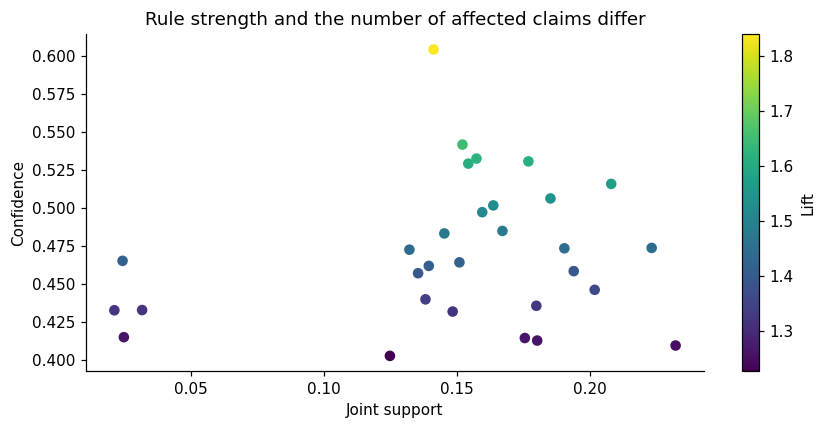

In [8]:
plt.figure(figsize=(8,4));points=plt.scatter(rules.support,rules.confidence,c=rules.lift,cmap='viridis',s=35)
plt.colorbar(points,label='Lift');plt.xlabel('Joint support');plt.ylabel('Confidence');plt.title('Rule strength and the number of affected claims differ')
plt.tight_layout();plt.show()

## 5. Chi-squared shows why sample size matters
We build a 2×2 table for one rule, then calculate its chi-squared distance from independence. Claims in a common storm or neighborhood are related. We therefore use this as a descriptive classroom calculation and do not claim independent-record statistical significance or a causal effect.

In [9]:
if len(rules):
    a=Bt[list(example.antecedents)].all(axis=1);b=Bt[TARGET]
    observed=pd.crosstab(a,b).reindex(index=[False,True],columns=[False,True],fill_value=0).to_numpy()
    expected=np.outer(observed.sum(axis=1),observed.sum(axis=0))/observed.sum()
    chi2=np.sum((observed-expected)**2/np.maximum(expected,1e-12))
    display(pd.DataFrame(observed,index=['A absent','A present'],columns=['outcome absent','outcome present']))
    print('Expected under independence:');display(pd.DataFrame(expected).round(1))
    print(f'Descriptive chi-squared: {chi2:,.1f}')

,outcome absent,outcome present
A absent,72028,23282
A present,11492,17553


Expected under independence:


,0,1
0,64012.6,31297.4
1,19507.4,9537.6


Descriptive chi-squared: 13,085.9


**Decision.** Report effect measures and counts together. We do not let a very small nominal p-value replace the question of practical value or the need to account for shared events. A large dataset can make a modest relationship look statistically impressive.

## 6. Freeze readable rules using earlier years only
A rule is only useful if it says more than one of its own facts. For example, "slab foundation AND zone AE" is not interesting if "slab foundation" alone gives the same lift. We call this the **lift gain over the best single fact**.

Our screening rule: support at least 2%, confidence at least 50%, lift at least 1.2, and a lift gain of at least 1.05 over the best single fact. We rank the retained rules by lift and freeze up to ten. These are exploratory rules, not a warning model.

In [10]:
single_lift={item:Bt.loc[Bt[item],TARGET].mean()/base_rate for item in B.columns if item!=TARGET}
rules['best single lift']=rules.antecedents.apply(lambda s:max(single_lift[x] for x in s))
rules['lift gain over best single fact']=rules.lift/rules['best single lift']
chosen=rules[(rules.support>=.02)&(rules.confidence>=.5)&(rules.lift>=1.2)&(rules['lift gain over best single fact']>=1.05)
             &rules.antecedents.apply(len).eq(2)].sort_values(['lift','leverage'],ascending=False).head(10).copy()
display(chosen[['IF','support','confidence','lift','best single lift','lift gain over best single fact']].round(3))
print('Retained earlier-year rules:',len(chosen))

,IF,support,confidence,lift,best single lift,lift gain over best single fact
465,Florida AND building older than 40,0.141,0.604,1.840,1.397,1.318
378,building older than 40 AND slab foundation,0.152,0.542,1.650,1.443,1.143
445,Florida AND slab foundation,0.157,0.533,1.622,1.443,1.124
366,slab foundation AND zone AE,0.177,0.531,1.616,1.443,1.120
425,hurricane within 100km AND slab foundation,0.154,0.529,1.612,1.443,1.117
357,named event AND slab foundation,0.208,0.516,1.571,1.443,1.089
360,single family AND slab foundation,0.185,0.506,1.542,1.443,1.069
370,five-day rain at least 150mm AND slab foundation,0.164,0.502,1.528,1.443,1.059


Retained earlier-year rules: 8


### 6.1 Recalculate the same measures on later claims
A higher later confidence can simply reflect more severe claims overall. Recomputing lift relative to the later base rate makes that distinction visible. We keep the frozen antecedents even when they weaken.

In [11]:
Btest=B.loc[test];later_base=Btest[TARGET].mean();checks=[]
for _,rule in chosen.iterrows():
    present=Btest[list(rule.antecedents)].all(axis=1)
    confidence=Btest.loc[present,TARGET].mean() if present.any() else np.nan
    support=(present&Btest[TARGET]).mean()
    checks.append({'IF':rule['IF'],'earlier confidence':rule.confidence,'later confidence':confidence,
        'earlier lift':rule.lift,'later lift':confidence/later_base if later_base else np.nan,
        'later support':support,'later matching claims':present.sum(),
        'best single fact later lift':max(Btest.loc[Btest[x],TARGET].mean() for x in rule.antecedents)/later_base})
checked=pd.DataFrame(checks,columns=['IF','earlier confidence','later confidence','earlier lift','later lift','later support','later matching claims','best single fact later lift']).set_index('IF')
checked['beats best single fact later']=checked['later lift']>checked['best single fact later lift']
print(f'Outcome share: earlier {base_rate:.1%}; later {later_base:.1%}')
display(checked.round(3));save_table(checked,'11_later_rules')

Outcome share: earlier 32.8%; later 48.4%


,earlier confidence,later confidence,earlier lift,later lift,later support,later matching claims,best single fact later lift,beats best single fact later
IF,,,,,,,,
Florida AND building older than 40,0.604,0.692,1.840,1.431,0.376,50285,1.194,True
building older than 40 AND slab foundation,0.542,0.690,1.650,1.427,0.367,49295,1.321,True
Florida AND slab foundation,0.533,0.706,1.622,1.460,0.356,46656,1.321,True
slab foundation AND zone AE,0.531,0.686,1.616,1.419,0.344,46495,1.321,True
hurricane within 100km AND slab foundation,0.529,0.464,1.612,0.959,0.058,11661,1.321,False
named event AND slab foundation,0.516,0.675,1.571,1.395,0.379,52124,1.321,True
single family AND slab foundation,0.506,0.683,1.542,1.412,0.333,45214,1.321,True
five-day rain at least 150mm AND slab foundation,0.502,0.462,1.528,0.955,0.088,17588,1.321,False


### 6.2 Which rules weaken?
A rule's performance can shift because of event mix, geography, building mix or incomplete external matches. These data do not identify one unique explanation. The later comparison is the evidence that a rule did or did not transfer.

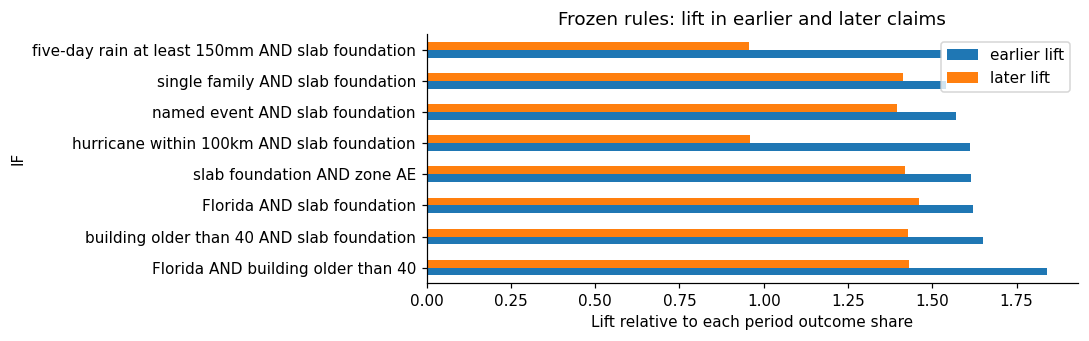

**Observed result:** 6 of 8 frozen rules still have lift above 1 in the later years, and **6** of 8 still beat their best single fact. The second number is the fairer test, because almost any fact linked to damage keeps a lift above 1.

In [12]:
if len(checked):
    checked[['earlier lift','later lift']].plot.barh(figsize=(10,max(3,len(checked)*.4)),title='Frozen rules: lift in earlier and later claims')
    plt.xlabel('Lift relative to each period outcome share');plt.tight_layout();plt.show()
    survived=checked['later lift'].gt(1).sum();better=checked['beats best single fact later'].sum()
    display(Markdown(f'**Observed result:** {survived} of {len(checked)} frozen rules still have lift above 1 in the later years, '
                     f'and **{better}** of {len(checked)} still beat their best single fact. '
                     'The second number is the fairer test, because almost any fact linked to damage keeps a lift above 1.'))

## 7. Why we do not invent property sequences
Lecture 12 groups repeated purchases by a stable customer ID. This claims file has a unique **claim** ID, not a reliable stable building or household ID. Redacted coordinates can refer to many properties. A latest payment date is not a complete payment history.

Therefore, sorting nearby claims by date would not establish a sequence of repeat losses for one property. Counting opening before latest payment would mainly rediscover how the timeline was defined. We discard those proposed sequential-mining steps.

Notebook 07 is a better use of the available time data: it studies event-level claim arrival counts and states its timing limits. True property sequences would require a stable property identifier and historical event records with suitable privacy controls.

## 8. What did this final step add?

| Earlier approach | What rules add | What rules still cannot prove |
|---|---|---|
| Single-feature EDA | A readable combination of two facts | That the facts cause damage |
| Clustering | Specific conditional associations rather than one label per claim | That combinations form separate natural classes |
| Prediction | Counts, support and base-rate-relative lift | That a readable rule matches the full classifier's accuracy |
| Anomaly review | An explanation of which facts commonly occur together | That an uncommon combination is an error or fraud |

**Keep:** simple transactions, multiple rule measures, earlier-year selection and later-year checks. **Discard:** confidence-only ranking, significance-only conclusions, and property histories inferred from redacted locations.

The final result is the reasoned comparison: we learned which representations are useful, which assumptions fail, and which questions the current data cannot answer. Adding a course method is useful only when the research question and record structure support it.

### Result in plain English

**6 of 8** frozen rules still have a lift above 1 in the later years, but only **6** of 8 beat their own best single fact. The rules describe claims we can see, not the chance that any building floods. We keep support, confidence, lift and excess counts together, and we do not mine building histories, because the file has no stable building ID.